# 06 — Probabilidades e Classes Desbalanceadas

O notebook 05 terminou com o **gradient boosting** na frente (AUC 0,929). Até aqui, olhamos principalmente para a **ordenação** (a AUC) e para as **classes** previstas. Mas os nossos modelos devolvem **probabilidades**, e no notebook 04 usamos essas probabilidades para escolher limiares.

Duas perguntas ficaram em aberto:
1. **As probabilidades merecem confiança?** Quando o modelo diz "70%", cerca de 70% dessas pessoas têm mesmo renda alta?
2. **O desbalanceamento atrapalha?** Uma recomendação muito comum é "equilibrar as classes" com **pesos** (`class_weight="balanced"`). Isso ajuda?

Neste notebook vamos:
- Conhecer a **calibração** e a **curva de calibração**
- Medir a qualidade das probabilidades com a **perda logarítmica** (*log loss*) e o **Brier score**
- Testar, com honestidade, o **`class_weight="balanced"`**
- Usar o **`CalibratedClassifierCV`** para consertar probabilidades distorcidas

> ⏱️ Este notebook leva cerca de **30 segundos** para rodar: algumas células treinam muitos modelos.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score

# Ferramentas novas deste notebook:
from sklearn.metrics import log_loss, brier_score_loss    # métricas da qualidade das probabilidades
from sklearn.calibration import calibration_curve         # dados da curva de calibração
from sklearn.calibration import CalibratedClassifierCV    # "conserta" as probabilidades de um modelo

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

df = fetch_openml("adult", version=2, as_frame=True).frame
X = df.drop(columns="class")
y = (df["class"] == ">50K").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

colunas_numericas = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
colunas_categoricas = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
colunas = colunas_numericas + colunas_categoricas
X_train = X_train[colunas]   # daqui em diante, só as colunas que usamos

Vamos reconstruir os modelos do notebook 05 e calcular, uma única vez, a probabilidade "fora da dobra" de cada pessoa do treino para cada modelo (como no notebook 04).

In [2]:
preparar_one_hot = ColumnTransformer([
    ("numericas", StandardScaler(), colunas_numericas),
    ("categoricas", Pipeline([
        ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
    ]), colunas_categoricas),
])
preparar_ordinal = ColumnTransformer([
    ("numericas", "passthrough", colunas_numericas),
    ("categoricas", Pipeline([
        ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("numerar", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ]), colunas_categoricas),
])

modelos = {
    "Logística": Pipeline([("preparar", preparar_one_hot), ("modelo", LogisticRegression(max_iter=1000))]),
    "Random forest (padrão)": Pipeline([
        ("preparar", preparar_ordinal),
        ("modelo", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)),
    ]),
    "Random forest (min_samples_leaf=10)": Pipeline([
        ("preparar", preparar_ordinal),
        ("modelo", RandomForestClassifier(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=42)),
    ]),
    "Gradient boosting": HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=42),
}

probabilidades = {}   # nome do modelo -> probabilidade de renda alta de cada pessoa do treino
for nome, modelo in modelos.items():
    probabilidades[nome] = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    print(f"{nome:<37} AUC {roc_auc_score(y_train, probabilidades[nome]):.4f}")

Logística                             AUC 0.9063


Random forest (padrão)                AUC 0.8969


Random forest (min_samples_leaf=10)   AUC 0.9179


Gradient boosting                     AUC 0.9284


## 🎓 Conceito: calibração

Um modelo é **bem calibrado** quando as suas probabilidades **batem com a realidade**: entre todas as pessoas para quem ele diz "70%", cerca de 70% têm de fato renda alta; entre as que recebem "10%", cerca de 10%; e assim por diante.

Analogia: a **previsão do tempo**. Um bom meteorologista não é só o que acerta "chove/não chove". É aquele em que, olhando todos os dias em que ele disse "70% de chance de chuva", choveu em mais ou menos 70% deles. Se choveu em 95% desses dias, ele é **inseguro demais** (subestima); se choveu em 40%, ele é **confiante demais** (exagera).

Repare que **calibração e ordenação são coisas diferentes**:
- A **AUC** pergunta: o modelo coloca as pessoas de renda alta **na frente** das de renda baixa?
- A **calibração** pergunta: os **números** que ele dá significam o que dizem?

Um modelo pode ordenar perfeitamente e ainda dar números distorcidos (por exemplo, multiplicando todas as probabilidades por 0,5: a ordem não muda, mas os números ficam errados).

**Quando a calibração importa?** Sempre que o **número** for usado, e não só a ordem: para escolher um limiar pelo custo dos erros (notebook 04), para calcular um valor esperado ("70% de chance × R\$ 1.000 de lucro") ou para mostrar a probabilidade para uma pessoa.

## 2. Calibração "à mão"

A forma mais simples de verificar a calibração: separar as pessoas em **faixas de probabilidade prevista** e comparar, em cada faixa, a probabilidade **média prevista** com a **taxa real** de renda alta.

In [3]:
prob_boosting = probabilidades["Gradient boosting"]

# pd.cut separa as probabilidades em 10 faixas de largura 0,1: [0; 0,1), [0,1; 0,2), ...
faixas = pd.cut(prob_boosting, bins=np.linspace(0, 1, 11), include_lowest=True)

tabela_calibracao = pd.DataFrame({
    "pessoas": pd.Series(prob_boosting).groupby(faixas, observed=True).size(),
    "probabilidade média prevista": pd.Series(prob_boosting).groupby(faixas, observed=True).mean(),
    # .values: usamos só os valores de y_train, sem o índice original (que não bateria com o da Series acima).
    "taxa real de renda alta": pd.Series(y_train.values).groupby(faixas, observed=True).mean(),
})
tabela_calibracao

,pessoas,probabilidade média prevista,taxa real de renda alta
"(-0.001, 0.1]",21071,0.0214,0.0206
"(0.1, 0.2]",3618,0.1469,0.1611
"(0.2, 0.3]",2393,0.2483,0.2674
"(0.3, 0.4]",2375,0.3488,0.3381
"(0.4, 0.5]",1795,0.4481,0.4501
"(0.5, 0.6]",1495,0.5489,0.5378
"(0.6, 0.7]",1496,0.6509,0.6330
"(0.7, 0.8]",1404,0.7472,0.7528
"(0.8, 0.9]",770,0.8444,0.8455
"(0.9, 1.0]",2656,0.9836,0.9872


**Conclusão:** as probabilidades do gradient boosting **batem muito bem** com a realidade. Em todas as faixas, a probabilidade média prevista e a taxa real ficam a menos de ~2 pontos percentuais uma da outra. Por exemplo, na faixa de 0,7 a 0,8, o modelo prevê em média 74,7%, e a taxa real é **75,3%**. Na faixa de 0,9 a 1,0, prevê 98,4%, e a real é **98,7%**.

Repare também em **quantas** pessoas há em cada faixa: 21.071 (54% do treino) recebem menos de 10%, e 2.656 recebem mais de 90%. O modelo tem bastante certeza sobre a maioria das pessoas, e as faixas do meio, onde ele está em dúvida, têm bem menos gente.

## 3. Curvas de calibração dos modelos

A **curva de calibração** é o gráfico dessa tabela: no eixo x, a probabilidade média prevista em cada faixa; no eixo y, a taxa real. Um modelo **perfeitamente calibrado** fica em cima da **diagonal**.
- Pontos **abaixo** da diagonal: o modelo **exagera** (diz 80%, mas só 60% são renda alta).
- Pontos **acima** da diagonal: o modelo é **inseguro** (diz 80%, mas 95% são).

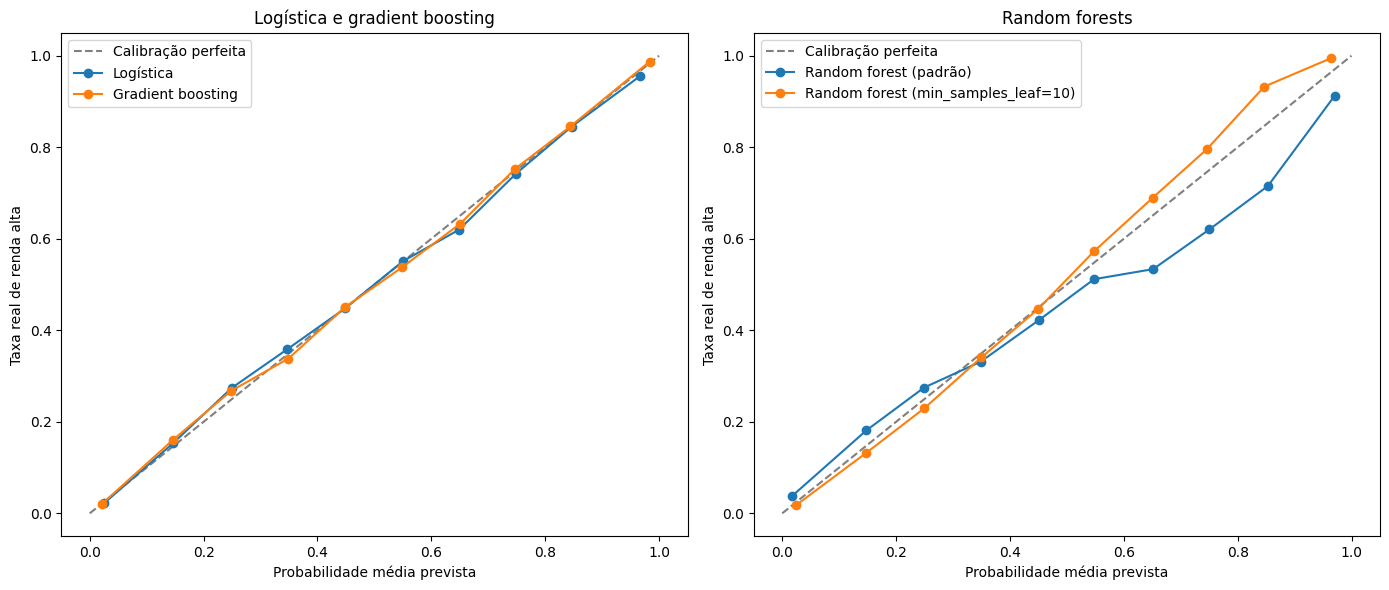

In [4]:
def desenhar_calibracao(nomes, ax, titulo):
    """Desenha a curva de calibração de vários modelos num mesmo gráfico."""
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Calibração perfeita")
    for nome in nomes:
        # calibration_curve faz o que fizemos à mão na seção 2: devolve a taxa real e a prevista de cada faixa.
        taxa_real, prob_media = calibration_curve(y_train, probabilidades[nome], n_bins=10)
        ax.plot(prob_media, taxa_real, marker="o", label=nome)
    ax.set_xlabel("Probabilidade média prevista")
    ax.set_ylabel("Taxa real de renda alta")
    ax.set_title(titulo)
    ax.legend(loc="upper left")


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
desenhar_calibracao(["Logística", "Gradient boosting"], axes[0], "Logística e gradient boosting")
desenhar_calibracao(["Random forest (padrão)", "Random forest (min_samples_leaf=10)"], axes[1], "Random forests")
plt.tight_layout()
plt.show()

**Conclusão:** - **Logística e gradient boosting (esquerda)** ficam praticamente em cima da diagonal: os dois são **bem calibrados**. Isso não é coincidência: os dois são treinados minimizando a **perda logarítmica** (a próxima seção), uma métrica que pune justamente probabilidades descalibradas.
- **Random forest padrão (direita, azul)** **exagera** nas probabilidades altas: quando ela diz ~75%, só ~62% têm renda alta; quando diz ~85%, só ~72%. São as folhas puras do notebook 05, que deixam as árvores confiantes demais.
- **Random forest com `min_samples_leaf=10` (laranja)** tem o defeito **oposto**: fica acima da diagonal nas probabilidades altas (diz ~75%, e a taxa real é ~80%; diz ~85%, e são ~93%). Ela é **insegura**: a média de muitas árvores "puxa" as probabilidades para o meio, e é raro todas as árvores concordarem em 0 ou 1.

## 🎓 Conceito: perda logarítmica e Brier score

A curva de calibração é ótima para **olhar**, mas para **comparar** modelos queremos um número. Existem duas métricas clássicas para a qualidade das probabilidades. Nas duas, **menor é melhor**.

**Brier score:** o erro quadrático médio entre a probabilidade e o que aconteceu (0 ou 1). É o MSE do ML-01 aplicado às probabilidades:
$$\text{Brier} = \text{média de } (p - y)^2$$

**Perda logarítmica (*log loss*):** para cada pessoa, olha a probabilidade que o modelo deu para a classe **que de fato aconteceu**, e calcula $-\log$ dela:
$$\text{log loss} = \text{média de } -\log(\text{probabilidade dada à classe real})$$

A log loss **pune com muita força os erros confiantes**. Para uma pessoa que tem renda alta:

| Probabilidade de renda alta prevista | Log loss dessa pessoa |
|---|---|
| 0,9 (acertou com confiança) | 0,11 |
| 0,5 (em dúvida) | 0,69 |
| 0,1 (errou com confiança) | 2,30 |
| 0,01 (errou com muita confiança) | 4,61 |

Analogia: um aluno que responde "não sei" perde poucos pontos; um que responde errado **com toda a certeza** perde muitos. A log loss é a métrica que a **regressão logística minimiza** durante o treino, e é também a métrica que o boosting usa para classificar.

In [5]:
qualidade = pd.DataFrame({
    nome: {
        "AUC": roc_auc_score(y_train, p),
        "log loss": log_loss(y_train, p),
        "Brier": brier_score_loss(y_train, p),
        "prob. média prevista": p.mean(),   # deveria ser próxima da proporção real (23,9%)
    }
    for nome, p in probabilidades.items()   # um dict comprehension montando uma coluna por modelo
}).T
qualidade

,AUC,log loss,Brier,prob. média prevista
Logística,0.9063,0.3188,0.1021,0.2393
Random forest (padrão),0.8969,0.4174,0.1064,0.2432
Random forest (min_samples_leaf=10),0.9179,0.2978,0.0947,0.2392
Gradient boosting,0.9284,0.2765,0.0882,0.2384


**Conclusão:** - O **gradient boosting** é o melhor em **todas** as métricas: maior AUC (0,928) e menores log loss (**0,277**) e Brier (**0,088**).
- A **random forest padrão** tem a pior log loss (**0,417**), bem pior que a da logística (0,319), mesmo tendo um Brier parecido. São os erros **confiantes** (probabilidades perto de 0 ou 1 que estavam erradas), que a log loss pune com força.
- Em todos os modelos, a **probabilidade média prevista** fica perto de **23,9%**, a proporção real de renda alta. Em média, nenhum deles infla ou encolhe as probabilidades; os problemas das florestas estão na **forma** da curva.

*Detalhe:* aqui a AUC é calculada com as probabilidades de todas as pessoas juntas, por isso pode diferir na 4ª casa decimal da média das 5 dobras do notebook 05 (por exemplo, 0,9284 contra 0,9285 no boosting).

## 🎓 Conceito: classes desbalanceadas e pesos de classe

Com 76% de `<=50K` e 24% de `>50K`, cada pessoa de renda alta "pesa" pouco no treino: o modelo pode errar muitas delas e ainda ter uma perda baixa no total. Uma técnica muito popular para isso é dar **pesos** às classes:

- Com `class_weight="balanced"`, cada erro numa pessoa da classe **rara** passa a custar mais no treino, na proporção inversa da frequência dela. Aqui, cada pessoa de renda alta passa a "valer" ~3 vezes mais que uma de renda baixa.
- O efeito esperado: o modelo passa a prever `>50K` com mais facilidade, e o **recall sobe**.

Outras técnicas com a mesma ideia: **subamostragem** (jogar fora parte da classe majoritária), **sobreamostragem** (repetir exemplos da minoritária) e o **SMOTE** (criar exemplos sintéticos da minoritária, com a biblioteca `imbalanced-learn`).

Analogia: num júri de talentos, os candidatos de uma cidade pequena recebem um "bônus" na nota para compensar serem poucos. Mas atenção: o bônus muda a **nota**, e não o **talento** de ninguém. Vamos ver se, no nosso caso, ele muda alguma coisa de verdade.

## 4. Testando o `class_weight="balanced"`

In [6]:
modelos_balanceados = {
    "Logística (balanced)": Pipeline([
        ("preparar", preparar_one_hot),
        ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "Gradient boosting (balanced)": HistGradientBoostingClassifier(
        categorical_features="from_dtype", class_weight="balanced", random_state=42
    ),
}
for nome, modelo in modelos_balanceados.items():
    probabilidades[nome] = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

limiares = np.arange(0.05, 0.96, 0.01)


def resumo(nome):
    """AUC, métricas no limiar 0,5, o melhor F1 (e em qual limiar) e a qualidade das probabilidades."""
    p = probabilidades[nome]
    previsto = (p >= 0.5).astype(int)
    f1_por_limiar = [f1_score(y_train, (p >= limiar).astype(int)) for limiar in limiares]
    return {
        "AUC": roc_auc_score(y_train, p),
        "precisão (0,5)": precision_score(y_train, previsto),
        "recall (0,5)": recall_score(y_train, previsto),
        "F1 (0,5)": f1_score(y_train, previsto),
        "melhor F1": max(f1_por_limiar),
        "limiar do melhor F1": limiares[np.argmax(f1_por_limiar)],   # np.argmax: a POSIÇÃO do maior valor
        "log loss": log_loss(y_train, p),
        "prob. média prevista": p.mean(),
    }


comparacao = pd.DataFrame({nome: resumo(nome) for nome in
                           ["Logística", "Logística (balanced)", "Gradient boosting", "Gradient boosting (balanced)"]}).T
comparacao

,AUC,"precisão (0,5)","recall (0,5)","F1 (0,5)",melhor F1,limiar do melhor F1,log loss,prob. média prevista
Logística,0.9063,0.7310,0.6001,0.6591,0.6896,0.33,0.3188,0.2393
Logística (balanced),0.9063,0.5671,0.8484,0.6798,0.6892,0.62,0.3912,0.3665
Gradient boosting,0.9284,0.7775,0.6504,0.7083,0.7273,0.39,0.2765,0.2384
Gradient boosting (balanced),0.9283,0.6065,0.8631,0.7124,0.7275,0.65,0.3317,0.3424


**Conclusão:** os pesos **não melhoraram** nenhum dos dois modelos de verdade:
- **A AUC não mudou** (0,9063 e 0,9063 na logística; 0,9284 e 0,9283 no boosting). Os pesos não fizeram o modelo **ordenar** as pessoas melhor.
- **No limiar 0,5**, o recall subiu muito (boosting: de 65,0% para **86,3%**) e a precisão caiu (de 77,8% para 60,7%). O F1 no limiar 0,5 até melhorou um pouco (0,708 → 0,712). É o mesmo efeito de **baixar o limiar**.
- **O melhor F1 possível é o mesmo:** 0,7273 contra 0,7275 no boosting, e 0,6896 contra 0,6892 na logística. A diferença é que, no modelo balanceado, ele é alcançado num limiar mais alto (0,65 em vez de 0,39).
- **As probabilidades ficaram infladas:** a probabilidade média prevista subiu de 23,8% para **34,2%** no boosting (e para 36,7% na logística), muito acima da proporção real de 23,9%. A log loss **piorou** (boosting: de 0,277 para 0,332).

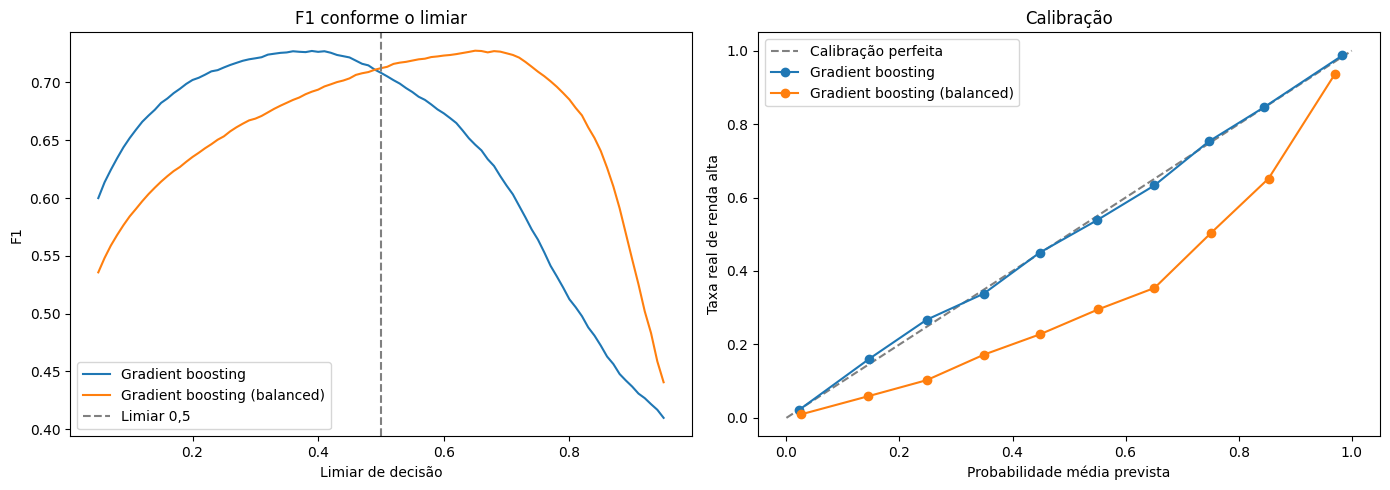

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Esquerda: o F1 em cada limiar, para o boosting normal e o balanceado.
for nome in ["Gradient boosting", "Gradient boosting (balanced)"]:
    f1_por_limiar = [f1_score(y_train, (probabilidades[nome] >= l).astype(int)) for l in limiares]
    axes[0].plot(limiares, f1_por_limiar, label=nome)
axes[0].axvline(0.5, color="gray", linestyle="--", label="Limiar 0,5")
axes[0].set_xlabel("Limiar de decisão")
axes[0].set_ylabel("F1")
axes[0].set_title("F1 conforme o limiar")
axes[0].legend()

# Direita: as curvas de calibração dos dois.
desenhar_calibracao(["Gradient boosting", "Gradient boosting (balanced)"], axes[1], "Calibração")
plt.tight_layout()
plt.show()

**Conclusão:** os dois gráficos resumem a história:
- **Esquerda:** a curva do F1 do modelo balanceado é praticamente a **mesma curva deslocada para a direita**. O pico tem a mesma altura (~0,727); só muda o limiar em que ele acontece. Os pesos **não criaram** nenhuma capacidade nova: só **mudaram a escala** das probabilidades.
- **Direita:** o modelo balanceado fica muito **abaixo da diagonal**: quando ele diz ~65%, só ~35% das pessoas têm renda alta; quando diz ~85%, só ~65%. Ele **exagera** de forma sistemática. Se alguém usasse esses números para calcular um valor esperado, ou mostrasse "65% de chance" a uma pessoa, estaria **enganando**.

**Lição honesta:** neste problema, `class_weight="balanced"` é só um jeito indireto (e com efeito colateral) de mover o limiar. O mesmo ganho se obtém ajustando o limiar do modelo normal, como no notebook 04, **sem estragar as probabilidades**.

## 5. Consertando probabilidades: `CalibratedClassifierCV`

E se já temos um modelo com probabilidades distorcidas, como o boosting balanceado? O `CalibratedClassifierCV` aprende uma **"tradução"** das probabilidades do modelo para probabilidades calibradas:
1. Divide o treino em dobras (validação cruzada **interna**).
2. Em cada rodada, treina o modelo nas outras dobras e observa, na dobra de fora, como as probabilidades dele se relacionam com a realidade.
3. Aprende uma curva que "conserta" essa relação. Com `method="isotonic"`, a curva pode ter qualquer formato, desde que sempre crescente (para **não mudar a ordem** das pessoas).

Analogia: uma balança que marca sempre 2 kg a mais. Em vez de jogá-la fora, você anota a correção e desconta sempre.

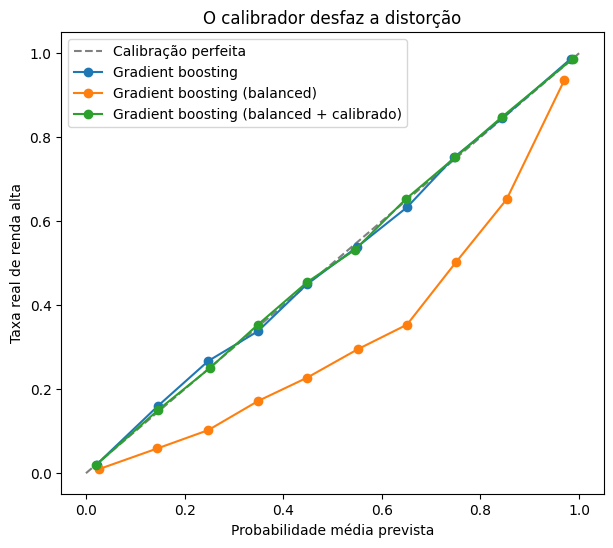

,AUC,"precisão (0,5)","recall (0,5)","F1 (0,5)",melhor F1,limiar do melhor F1,log loss,prob. média prevista
Gradient boosting,0.9284,0.7775,0.6504,0.7083,0.7273,0.39,0.2765,0.2384
Gradient boosting (balanced),0.9283,0.6065,0.8631,0.7124,0.7275,0.65,0.3317,0.3424
Gradient boosting (balanced + calibrado),0.9284,0.7796,0.6421,0.7042,0.7271,0.34,0.2782,0.2390


In [8]:
# ⏱️ Célula um pouco mais lenta (~10 segundos): 5 dobras de fora × 5 dobras internas.
boosting_balanceado_calibrado = CalibratedClassifierCV(
    HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight="balanced", random_state=42),
    method="isotonic",   # curva de correção flexível (só exige que seja crescente)
    cv=5,                # validação cruzada interna, para aprender a correção
)
probabilidades["Gradient boosting (balanced + calibrado)"] = cross_val_predict(
    boosting_balanceado_calibrado, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

fig, ax = plt.subplots(figsize=(7, 6))
desenhar_calibracao(["Gradient boosting", "Gradient boosting (balanced)", "Gradient boosting (balanced + calibrado)"],
                    ax, "O calibrador desfaz a distorção")
plt.show()

pd.DataFrame({nome: resumo(nome) for nome in
              ["Gradient boosting", "Gradient boosting (balanced)", "Gradient boosting (balanced + calibrado)"]}).T

**Conclusão:** o calibrador **desfez** a distorção: a curva verde voltou para a diagonal, a probabilidade média voltou para **23,9%**, e a log loss caiu de 0,332 para **0,278**, praticamente a mesma do boosting normal (0,277). A AUC ficou igual (0,9284), porque a correção isotônica não muda a ordem das pessoas.

Mas repare no resultado final: o modelo "balanceado + calibrado" ficou **praticamente idêntico ao boosting normal**, com o mesmo melhor F1 (0,727), as mesmas probabilidades e a mesma AUC. Demos uma volta inteira para chegar ao mesmo lugar, e com um modelo **mais complexo** e mais lento.

O `CalibratedClassifierCV` continua sendo uma ferramenta valiosa para modelos que **já nascem** descalibrados, como a random forest. Mas o melhor é não distorcer as probabilidades sem necessidade.

## 6. Quando o desbalanceamento é um problema de verdade?

Os resultados deste notebook podem parecer contrariar muitos tutoriais, que tratam o desbalanceamento como um problema que **sempre** precisa ser "consertado". Vale separar duas situações:

**1. Poucos exemplos da classe rara.** Se tivéssemos só 50 pessoas de renda alta, o modelo teria pouquíssimos exemplos para aprender como elas são. Isso é um problema real, mas de **falta de dados**, e pesos ou reamostragem não criam informação nova. Aqui temos **9.349** pessoas de renda alta no treino: informação de sobra.

**2. A proporção em si (24% × 76%).** Ela não impede um bom modelo de **ordenar** bem as pessoas (AUC) nem de dar **probabilidades** corretas. O que ela faz é deixar o limiar 0,5 inadequado para métricas como o F1 ou o recall. E a solução direta para isso é **ajustar o limiar** (notebook 04), sem distorcer as probabilidades.

| Abordagem | Ordenação (AUC) | Probabilidades | Melhor F1 possível |
|---|---|---|---|
| Modelo normal + limiar 0,5 | ✅ | ✅ calibradas | ❌ não alcança (o limiar 0,5 não é o melhor para o F1) |
| `class_weight="balanced"` + limiar 0,5 | ✅ igual | ❌ infladas | ⚠️ chega mais perto, mas sem garantia |
| **Modelo normal + limiar ajustado** | ✅ igual | ✅ calibradas | ✅ alcança |

**Regra prática:** comece com o modelo normal e ajuste o limiar para a métrica que importa. Use pesos ou reamostragem só se, **testando**, eles melhorarem algo que o ajuste do limiar não melhora.

## 7. Resumo e próximos passos

**Qualidade das probabilidades (validação cruzada no treino)**

| Modelo | AUC | Log loss | Brier | Calibração |
|---|---|---|---|---|
| Logística | 0,906 | 0,319 | 0,102 | ✅ boa |
| Random forest (padrão) | 0,897 | 0,417 | 0,106 | ❌ exagera |
| Random forest (`min_samples_leaf=10`) | 0,918 | 0,298 | 0,095 | ⚠️ insegura |
| **Gradient boosting** | **0,928** | **0,277** | **0,088** | ✅ boa |
| Gradient boosting (balanced) | 0,928 | 0,332 | — | ❌ exagera muito |
| Gradient boosting (balanced + calibrado) | 0,928 | 0,278 | — | ✅ boa |

**Conceitos que você aprendeu**
- **Calibração:** as probabilidades batem com a realidade? Calibração ≠ ordenação (AUC).
- **Curva de calibração** e como ler "exagerado" (abaixo da diagonal) e "inseguro" (acima).
- **Log loss** (pune erros confiantes) e **Brier score** (erro quadrático das probabilidades).
- **Pesos de classe** (`class_weight="balanced"`): no nosso caso, equivalem a mover o limiar e **estragam** as probabilidades.
- **`CalibratedClassifierCV`** com `method="isotonic"` para consertar probabilidades.
- Quando o desbalanceamento é um problema de verdade (poucos exemplos) e quando **ajustar o limiar** basta.

**Python novo:** `log_loss`, `brier_score_loss`, `calibration_curve`, `CalibratedClassifierCV`, `pd.cut(..., include_lowest=True)`, `.values` para ignorar o índice, `np.argmax` e funções que desenham num `ax` recebido como argumento.

**O modelo final**

Juntando tudo o que aprendemos, o modelo final da trilha será o **gradient boosting com as configurações padrão** (notebook 05), com probabilidades bem calibradas, e com o **limiar ajustado** para o F1 por validação cruzada (notebook 04). Sem pesos de classe.

**Próximo notebook (07):** avaliação final e interpretação. Vamos finalmente abrir o **conjunto de teste**, guardado desde o notebook 02, e ver se as estimativas da validação cruzada se confirmam. Depois vamos entender **o que o modelo usa** (*permutation importance*), **medir se ele trata grupos de forma diferente** (*fairness*: sexo e raça, como prometido no notebook 01), salvar o modelo e discutir os limites do seu uso.